# Espace des embeddings — voir la géométrie : réduction de dimension et banc de modèles

Le [03-Embeddings](03-Embeddings-From-Scratch.ipynb) a construit des vecteurs **à la main** : la PMI puis le skip-gram y faisaient émerger des voisins cohérents, et l'on mesurait la géométrie par des similarités une à une. Mais un espace de 384 dimensions ne se **voit** pas. Ce notebook s'attaque à ce qui manque encore à la série :

- **réduire** la dimension pour **voir** l'espace — une PCA construite à la main (géométrie linéaire, variance expliquée), puis un t-SNE via son implémentation de référence `sklearn` (non-linéaire, voisinages locaux) ;
- **comparer des modèles** : un banc de trois encodeurs multilingues exécutés localement encode le **même corpus français** — la référence de la série, un modèle à architecture différente, et un modèle au contrat d'usage explicite (préfixes `query:` / `passage:`) ;
- **mesurer** ce que chaque espace sait des thèmes (silhouette, voisins croisés, contrôle négatif) et ce que chaque réduction y perd.

La question directrice : **trois modèles voient-ils la même chose, et combien de cette chose survit à la projection en deux axes ?**

Prérequis : le vocabulaire de la similarité cosinus et des voisins sémantiques du [03-Embeddings](03-Embeddings-From-Scratch.ipynb). Aucun GPU requis : tout s'exécute sur CPU en quelques minutes (le premier appel télécharge les trois modèles, environ un gigaoctet au total).


## 1. Objectif — trois modèles, deux réductions, une question

Un embedding de phrase est fabriqué par un modèle entraîné : deux modèles différents produisent deux espaces **différents** — dimensions différentes, distances différentes, thèmes plus ou moins séparés. La série utilise pour l'instant un seul encodeur, pris comme un outil. Ici on le met dans un banc :

| Modèle | Dimensions | Ce qui le distingue |
|---|---|---|
| `paraphrase-multilingual-MiniLM-L12-v2` | 384 | la référence de la série (01, 02) — distillation multilingue |
| `distiluse-base-multilingual-cased-v1` | 512 | autre lignée (Universal Sentence Encoder distillé), 512 dimensions |
| `intfloat/multilingual-e5-small` | 384 | contrat d'usage **explicite** : préfixer les phrases (`query:` / `passage:`) |

Sur ces trois espaces, deux familles de réductions :

- **PCA** (à la main) : projection **linéaire** qui maximise la variance conservée — les axes restent des directions de l'espace d'origine, les distances globales sont approximativement préservées ;
- **t-SNE** (organ `sklearn.manifold.TSNE`) : réduction **non linéaire** qui préserve les voisinages locaux — les amas ressortent, mais les échelles entre amas ne veulent plus rien dire.

La comparaison est **mesurée** à chaque étape (silhouette, médianes intra/inter-thèmes, paires témoins), jamais affirmée sur l'aspect d'une figure.


## 2. Le même corpus français, six thèmes

Soixante phrases, six thèmes équilibrés. Le corpus est **déterministe** (aucun tirage aléatoire) : deux exécutions produisent les mêmes tableaux. Chaque thème est un domaine vocabulaire propre — cuisine, finance, sport, médecine, technologie, musique — pour qu'un espace sémantique honnête sépare les six groupes.


In [1]:
CORPUS = {
    "cuisine": [
        "La pâte à choux monte grâce à la vapeur emprisonnée dans l'oeuf.",
        "Un feu doux évite que le caramel ne cristallise prématurément.",
        "Le levain doit être rafraîchi toutes les douze heures pour rester actif.",
        "La cuisson sous vide conserve le jus de la viande à température constante.",
        "On monte une sauce hollandaise en émulsionnant le beurre clarifié.",
        "Le dosage du sel se fait progressivement pour ne pas briser la fermentation.",
        "Une marinade acide dénature les protéines en surface du poisson.",
        "Le four à pain doit atteindre une température homogène avant d'enfourner.",
        "La ricotta s'obtient en chauffant le lactosérum résiduel de la fabrication.",
        "Le beurre noisette doit son parfum aux solides du lait caramélisés.",
    ],
    "finance": [
        "La duration mesure la sensibilité d'une obligation aux taux d'intérêt.",
        "Un portefeuille diversifié réduit le risque spécifique de chaque ligne.",
        "L'effet de levier amplifie les gains comme les pertes du capital investi.",
        "La volatilité implicite reflète le prix que le marché paie l'incertitude.",
        "Un ordre à cours limité garantit le prix mais pas l'exécution.",
        "Le rendement d'un dividende se calcule par rapport au cours d'achat.",
        "La couverture delta-neutre immunise une position contre les petits mouvements.",
        "Les frais de gestion composés rognent la performance sur longue période.",
        "Un triangle de conversion signale un arbitrage entre trois devises.",
        "La prime de risque exigée compense l'illiquidité de l'actif sous-jacent.",
    ],
    "sport": [
        "Le coureur règle sa foulée pour économiser le glycogène sur marathon.",
        "Un gardien anticipe la trajectoire en lisant l'appui du tireur.",
        "L'entraînement fractionné alterne efforts intenses et récupération active.",
        "La période de préparation vise un pic de forme à la date cible.",
        "Le contre-pied fige le défenseur sur l'appel de balle inverse.",
        "Une échographie de fatigue peut révéler une lésion avant la douleur.",
        "Le braquet adapté maintient la cadence de pédalage en côte.",
        "La tactique de course protège le leader des vents de face.",
        "Un échauffement progressif prépare les articulations à l'effort.",
        "Le suivi de la charge d'entraînement prévient le surentraînement.",
    ],
    "medecine": [
        "L'antibiorésistance survient quand les bactéries survivent au traitement.",
        "La pression artérielle se mesure au bras, au repos, à plusieurs reprises.",
        "Un vaccin expose le système immunitaire à un antigène atténué.",
        "L'inflammation chronique fragilise les parois des vaisseaux.",
        "La posologie est ajustée selon le poids et la fonction rénale.",
        "Un taux d'hémoglobine bas signale une anémie à explorer.",
        "La radiographie thoracique montre l'extension de la pneumopathie.",
        "Le diabète de type deux altère la régulation du glucose sanguin.",
        "Une rééducation progressive restaure l'amplitude de l'articulation.",
        "Le consentement éclairé précède tout acte chirurgical programmé.",
    ],
    "technologie": [
        "Le ramasse-miettes libère la mémoire des objets inaccessibles.",
        "Une clé de cache invalidée force le recalcul de la page.",
        "La latence de bout en bout cumule chaque saut du réseau.",
        "Un index B-tree accélère les requêtes par intervalle.",
        "La quantification des poids réduit l'empreinte mémoire du modèle.",
        "Un test de charge révèle le point de rupture du service.",
        "Le protocole de consensus garantit l'ordre des écritures répliquées.",
        "La télémétrie agrège les métriques de tous les noeuds du cluster.",
        "Un repli de version isole la régression introduite par le déploiement.",
        "La normalisation du schéma élimine la redondance des attributs.",
    ],
    "musique": [
        "La gamme tempérée divise l'octave en douze demi-tons égaux.",
        "Un accord de septième ajoute une tension qui demande résolution.",
        "Le tempo rubato laisse le soliste dévier légèrement du métronome.",
        "Le registre grave du violoncelle porte la basse du quatuor.",
        "Un motif de trois notes revient à chaque exposition du thème.",
        "L'orchestration confie le contrepoint aux bois dans le trio.",
        "Le souffle du hautboïste coupe la phrase musicale en archets.",
        "Une modulation en sous-dominante assombrit la fin du refrain.",
        "Le réglage de la caisse claire se fait à l'oreille, au casque.",
        "La forme sonate expose, développe puis réexpose les deux thèmes.",
    ],
}

THEMES = list(CORPUS)
PHRASES, LABELS = [], []
for theme in THEMES:
    for phrase in CORPUS[theme]:
        PHRASES.append(phrase)
        LABELS.append(theme)

print(f"{len(PHRASES)} phrases, {len(THEMES)} themes :", {t: len(CORPUS[t]) for t in THEMES})


60 phrases, 6 themes : {'cuisine': 10, 'finance': 10, 'sport': 10, 'medecine': 10, 'technologie': 10, 'musique': 10}


### Lecture du résultat

Soixante phrases, dix par thème : l'équilibrage importe, car la silhouette et les médianes intra/inter-thèmes comparent des groupes de même taille. Le corpus ne contient aucune phrase ambigue à dessein — les thèmes frontière sont l'objet de l'exercice 2.


## 3. Le banc de trois modèles

Les trois encodeurs sont chargés sur CPU. Chaque modèle encode les soixante phrases ; on mesure la **latence moyenne par phrase** et la **dimension** de l'espace produit. Le E5 impose son préfixe : les phrases du corpus sont des documents, donc `passage: `. C'est le contrat documenté du modèle (sa carte de modèle) — ce carnet ne mesure pas ce que coûterait son omission, mais la section 5 montre, elle, mesurée, une conséquence de son espace de similarités brutes.


In [2]:
import time
import os
import numpy as np

# Cache Hugging Face sans liens symboliques (Windows) et sans barres de progression :
# sans ces deux reglages, l'avertissement de repli et les widgets de telechargement
# nomment des chemins de la machine d'execution dans la sortie du carnet.
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

from sentence_transformers import SentenceTransformer

MODELES = {
    "minilm": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    "distiluse": "sentence-transformers/distiluse-base-multilingual-cased-v1",
    "e5": "intfloat/multilingual-e5-small",
}
PREFIXE = {"minilm": "", "distiluse": "", "e5": "passage: "}

Espaces = {}   # nom -> matrice (60, dim), lignes normalisées
Temps = {}     # nom -> secondes par phrase (encodage seul)

for nom, nom_hf in MODELES.items():
    modele = SentenceTransformer(nom_hf, device="cpu")
    entrees = [PREFIXE[nom] + p for p in PHRASES]
    t0 = time.perf_counter()
    E = modele.encode(entrees, batch_size=16, convert_to_numpy=True,
                      normalize_embeddings=True, show_progress_bar=False)
    dt = time.perf_counter() - t0
    Espaces[nom] = E.astype(np.float64)
    Temps[nom] = dt / len(PHRASES)
    print(f"{nom:10s} {nom_hf}")
    print(f"           dimension {E.shape[1]}, latence {Temps[nom]*1000:.1f} ms/phrase")


W1023 00:19:25.387000 41724 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


minilm     sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
           dimension 384, latence 10.1 ms/phrase


distiluse  sentence-transformers/distiluse-base-multilingual-cased-v1
           dimension 512, latence 13.2 ms/phrase


e5         intfloat/multilingual-e5-small
           dimension 384, latence 8.3 ms/phrase


In [3]:
REF = "minilm"   # la référence de la série : les réductions de la section 6 portent sur elle
print(f"Modele de reference pour les reductions : {REF} ({MODELES[REF]})")
print(f"Espaces encodes : { {n: E.shape for n, E in Espaces.items()} }")


Modele de reference pour les reductions : minilm (sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2)
Espaces encodes : {'minilm': (60, 384), 'distiluse': (60, 512), 'e5': (60, 384)}


### Lecture du résultat — la dimension et la latence ne préjugent pas de la qualité

Trois espaces, trois dimensions (384, 512, 384), des latences du même ordre. Rien ici ne dit lequel sépare le mieux les thèmes : c'est la question de la section suivante, et elle se mesure, elle ne se devine pas sur le nombre de paramètres.


## 4. Ce que chaque espace sait des thèmes

Deux mesures par modèle :

- la **silhouette cosinus** sur les étiquettes de thème — proche de 1 : chaque phrase est plus proche de son thème que des autres ; proche de 0 : les thèmes se chevauchent ;
- les **médianes de similarité** intra-thème (paires de phrases d'un même thème) et inter-thèmes (paires de thèmes différents) — l'écart entre les deux est la marge de séparation.


In [4]:
from sklearn.metrics import silhouette_score
from itertools import combinations

def medians_intra_inter(E, labels):
    n = E.shape[0]
    sims = E @ E.T
    intra, inter = [], []
    for i, j in combinations(range(n), 2):
        (intra if labels[i] == labels[j] else inter).append(sims[i, j])
    return float(np.median(intra)), float(np.median(inter))

labels_arr = np.array(LABELS)
print(f"{'modele':10s} {'silhouette':>10s} {'intra':>8s} {'inter':>8s} {'marge':>8s}")
for nom, E in Espaces.items():
    sil = silhouette_score(E, labels_arr, metric="cosine")
    intra, inter = medians_intra_inter(E, LABELS)
    print(f"{nom:10s} {sil:10.3f} {intra:8.3f} {inter:8.3f} {intra - inter:8.3f}")


modele     silhouette    intra    inter    marge


minilm          0.121    0.261    0.097    0.164
distiluse       0.044    0.169    0.093    0.076
e5              0.053    0.882    0.869    0.013


In [5]:
# Trois phrases sonde : ou chaque modele place-t-il ses voisins ?
SONDES = [0, 27, 50]   # une phrase cuisine, une sport, une musique
for idx in SONDES:
    print(f"Sonde : {PHRASES[idx]!r}  (theme vrai : {LABELS[idx]})")
    for nom, E in Espaces.items():
        sims = E @ E[idx]
        ordre = np.argsort(-sims)
        voisins = [(PHRASES[k], LABELS[k], float(sims[k])) for k in ordre[1:4]]
        detail = " | ".join(f"[{lab}] {p[:38]}... {s:.2f}" for p, lab, s in voisins)
        print(f"  {nom:10s} {detail}")
    print()


Sonde : "La pâte à choux monte grâce à la vapeur emprisonnée dans l'oeuf."  (theme vrai : cuisine)
  minilm     [cuisine] On monte une sauce hollandaise en émul... 0.55 | [cuisine] Le beurre noisette doit son parfum aux... 0.49 | [cuisine] Le four à pain doit atteindre une temp... 0.48
  distiluse  [cuisine] La cuisson sous vide conserve le jus d... 0.42 | [cuisine] On monte une sauce hollandaise en émul... 0.38 | [cuisine] La ricotta s'obtient en chauffant le l... 0.31
  e5         [cuisine] La ricotta s'obtient en chauffant le l... 0.92 | [sport] Le contre-pied fige le défenseur sur l... 0.91 | [cuisine] Le beurre noisette doit son parfum aux... 0.90

Sonde : 'La tactique de course protège le leader des vents de face.'  (theme vrai : sport)
  minilm     [sport] Le coureur règle sa foulée pour économ... 0.51 | [sport] Le contre-pied fige le défenseur sur l... 0.43 | [sport] Le braquet adapté maintient la cadence... 0.43
  distiluse  [sport] Un gardien anticipe la trajectoire en ... 0.

### Lecture du résultat — trois espaces, combien d'accord ?

**Le tableau de la section 4, d'abord.** La référence de la série (MiniLM) sépare le mieux les six thèmes : silhouette 0,121, médiane intra 0,261 contre inter 0,097, soit une marge de 0,164. DistilUSE suit avec une marge moitié moindre (0,076) et une silhouette de 0,044. E5 affiche une marge de 0,013 seulement — ses similarités sont toutes massées entre 0,87 et 0,88, un espace **concentré** dont la section 5 mesure la conséquence.

**Les voisins, ensuite — et ils ne se ressemblent pas d'un modèle à l'autre.** Sur la sonde cuisine (pâte à choux), MiniLM et DistilUSE placent trois voisins de cuisine sur trois ; E5 en place deux sur trois — sa **deuxième** voisine est une phrase sport, à 0,91, à peine sous la première (0,92). Sur la sonde musique (gamme tempérée), **aucun** modèle ne retrouve majoritairement son thème : MiniLM propose deux phrases de technologie et une de cuisine, DistilUSE une seule phrase de musique, E5 une seule également — les trois à des similarités quasi égales (0,90). L'accord entre modèles se lit donc sur les **thèmes** des voisins, et il est partiel : les trois espaces s'accordent sur la cuisine, aucun ne s'accorde sur la musique.


## 5. Contrôle négatif — des paires censées être éloignées

Une silhouette haute pourrait tricher en collant tout le corpus en un seul bloc (tout proche de tout). Le contrôle : des paires de thèmes **éloignés par construction** (cuisine contre technologie, musique contre finance...) doivent rester nettement moins similaires que la médiane intra-thème. Cinq paires témoins, mesurées sur les trois espaces.


In [6]:
PAIRS_LOINTAINES = [
    (0, 50),   # pate a choux (cuisine)     vs gamme temperee (musique)
    (3, 53),   # cuisson sous vide (cuisine) vs forme sonate (musique)
    (10, 40),  # duration (finance)          vs ramasse-miettes (technologie)
    (15, 30),  # dividende (finance)         vs antibioresistance (medecine)
    (20, 44),  # foulee marathon (sport)     vs quantification (technologie)
]
print(f"{'paire':28s} {'minilm':>8s} {'distiluse':>10s} {'e5':>8s}")
for i, j in PAIRS_LOINTAINES:
    lib = f"{LABELS[i][:4]}/{LABELS[j][:4]} ({i}-{j})"
    scores = "".join(f"{float(Espaces[n][i] @ Espaces[n][j]):{10 if n == 'distiluse' else 8}.3f}"
                     for n in ["minilm", "distiluse", "e5"])
    print(f"{lib:28s}{scores}")
print()
for nom, E in Espaces.items():
    loin = np.median([float(E[i] @ E[j]) for i, j in PAIRS_LOINTAINES])
    intra, inter = medians_intra_inter(E, LABELS)
    print(f"{nom:10s} mediane des paires lointaines {loin:.3f} "
          f"| intra-theme {intra:.3f} | ecart {intra - loin:.3f}")


paire                          minilm  distiluse       e5
cuis/musi (0-50)               0.090     0.209   0.880
cuis/musi (3-53)              -0.013     0.113   0.871
fina/tech (10-40)              0.087     0.052   0.869
fina/mede (15-30)             -0.031     0.073   0.883
spor/tech (20-44)              0.230     0.033   0.856

minilm     mediane des paires lointaines 0.087 | intra-theme 0.261 | ecart 0.174
distiluse  mediane des paires lointaines 0.073 | intra-theme 0.169 | ecart 0.096
e5         mediane des paires lointaines 0.871 | intra-theme 0.882 | ecart 0.010


### Lecture du résultat — deux espaces passent le contrôle, le troisième non

**MiniLM et DistilUSE passent le contrôle** : leurs paires lointaines restent médianes à 0,087 et 0,073, contre 0,261 et 0,169 intra-thème — écarts de 0,174 et 0,096. La séparation mesurée à la section 4 n'y est donc pas un artefact : les thèmes éloignés le restent phrase par phrase.

**E5 échoue à ce contrôle, et c'est une mesure, pas une anomalie de code.** Ses paires lointaines sont médianes à 0,871, contre 0,882 intra-thème : un écart de 0,010, plus de dix fois plus petit que celui de MiniLM. Ses similarités brutes *passage-passage* sont toutes tassées autour de 0,87 — deux phrases de thèmes sans rapport y sont presque aussi proches que deux phrases du même thème. C'est cohérent avec le contrat du modèle : E5 est entraîné à apparier une **question** (`query: `) à un **passage** (`passage: `), pas deux passages entre eux. Comparer des documents à des documents sort de son usage, et l'espace répond alors « tout est proche de tout ». La leçon du contrôle est double : il attrape bien un espace qui ne discrimine pas par similarité brute, et il rappelle qu'un modèle se juge dans son contrat d'usage.


## 6. PCA from scratch — projeter 384 dimensions sur deux axes

La PCA cherche les deux directions de l'espace qui **conservent le plus de variance** du nuage. Construite à la main, elle tient en trois gestes : centrer la matrice, calculer la SVD, lire les composantes et les valeurs singulières. La projection 2D est le produit du nuage centré par les deux premières lignes de `Vt` ; la variance expliquée de l'axe k vaut `S[k]**2 / somme(S**2)`.

La validation se fait contre l'organ natif `sklearn.decomposition.PCA` : à signe près (le signe d'une composante est arbitraire), les deux doivent coïncider.


In [7]:
def pca_from_scratch(E, k=2):
    # Etape 1 : centrer (la PCA ne voit que les ecarts a la moyenne).
    C = E - E.mean(axis=0)
    # Etape 2 : SVD — les lignes de Vt sont les directions principales.
    U, S, Vt = np.linalg.svd(C, full_matrices=False)
    # Etape 3 : projection et variance expliquee.
    proj = C @ Vt[:k].T
    var_expliquee = S**2 / np.sum(S**2)
    return proj, var_expliquee, Vt

E_REF = Espaces[REF]
PROJ, VAR_EXPLIQUEE, VT = pca_from_scratch(E_REF)
cumul = np.cumsum(VAR_EXPLIQUEE)
print("Variance expliquee par axe :", np.round(VAR_EXPLIQUEE[:4], 4))
print("Cumul (axes 1..5)         :", np.round(cumul[:5], 4))
print(f"Deux axes conservent {(VAR_EXPLIQUEE[0] + VAR_EXPLIQUEE[1]) * 100:.1f} % de la variance totale")


Variance expliquee par axe : [0.0866 0.0777 0.0572 0.0515]
Cumul (axes 1..5)         : [0.0866 0.1643 0.2215 0.2731 0.3174]
Deux axes conservent 16.4 % de la variance totale


In [8]:
from sklearn.decomposition import PCA

pca_organ = PCA(n_components=2).fit(E_REF - E_REF.mean(axis=0))
coincidence = np.allclose(np.abs(pca_organ.components_), np.abs(VT[:2]), atol=1e-8)
print("Composantes |from scratch| == |sklearn PCA| (signes pres) :", coincidence)
print("Variance expliquee sklearn :", np.round(pca_organ.explained_variance_ratio_, 4))


Composantes |from scratch| == |sklearn PCA| (signes pres) : True
Variance expliquee sklearn : [0.0866 0.0777]


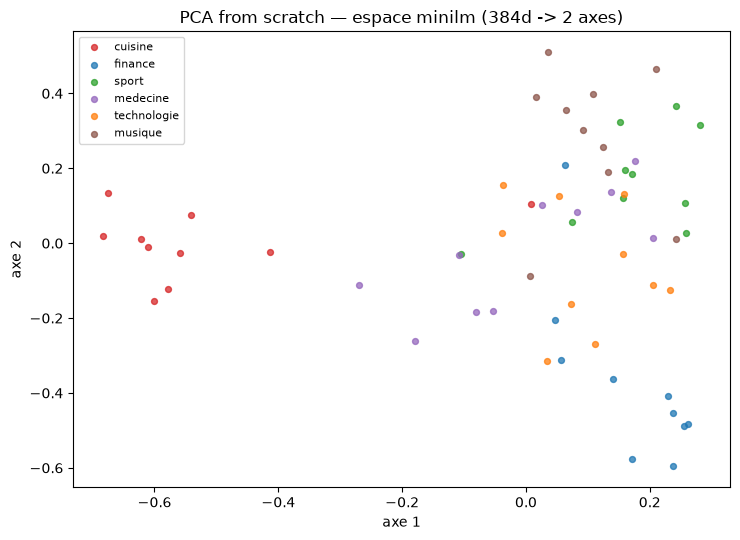

In [9]:
import matplotlib
import matplotlib.pyplot as plt

COULEURS = {"cuisine": "#d62728", "finance": "#1f77b4", "sport": "#2ca02c",
            "medecine": "#9467bd", "technologie": "#ff7f0e", "musique": "#8c564b"}

def nuage(proj, titre, ax):
    for theme in THEMES:
        masque = np.array(LABELS) == theme
        ax.scatter(proj[masque, 0], proj[masque, 1], s=18, alpha=0.75,
                   color=COULEURS[theme], label=theme)
    ax.set_title(titre)
    ax.set_xlabel("axe 1")
    ax.set_ylabel("axe 2")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
nuage(PROJ, f"PCA from scratch — espace {REF} (384d -> 2 axes)", ax)
ax.legend(loc="best", fontsize=8, framealpha=0.8)
plt.tight_layout()
plt.show()


### Lecture du résultat — deux axes, structure globale

Deux axes ne portent que **16,4 %** de la variance totale, mais ils ordonnent déjà les thèmes : sur la figure, les phrases de cuisine forment un amas à gauche de l'axe 1, celles de finance un amas à droite, et les quatre autres thèmes se chevauchent au centre. La séparation existe donc sur les premières directions, sans être nette partout — ce que la section 8 chiffre (silhouette du plan 0,107 contre 0,121 dans l'espace natif). Ce que la PCA ne montre pas : les voisinages fins à l'intérieur des amas ; c'est le travail du t-SNE.


## 7. t-SNE — l'organ non linéaire, ce qu'il gagne et ce qu'il invente

`t-SNE` (organ natif `sklearn.manifold.TSNE`) optimise une projection qui respecte les **voisinages locaux** : deux phrases proches dans l'espace d'origine restent proches sur le plan. Le prix : les **distances entre amas** et les **échelles** de la figure ne veulent plus rien dire — un grand écart sur le plan n'est pas un grand écart dans l'espace. La perplexité (~ le nombre de voisins considérés) se règle à la taille du corpus : huit pour soixante phrases, avec initialisation PCA et graine fixée pour la reproductibilité.


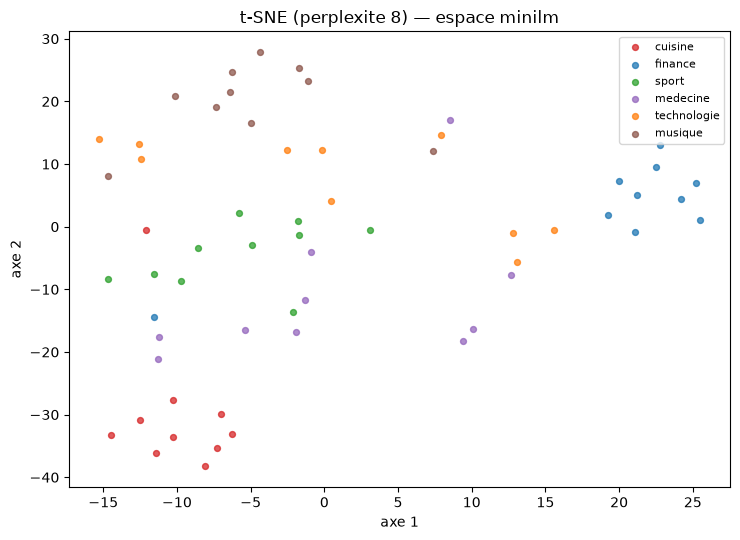

In [10]:
from sklearn.manifold import TSNE

PROJ_TSNE = TSNE(n_components=2, perplexity=8, init="pca",
                 random_state=42).fit_transform(E_REF)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
nuage(PROJ_TSNE, f"t-SNE (perplexite 8) — espace {REF}", ax)
ax.legend(loc="best", fontsize=8, framealpha=0.8)
plt.tight_layout()
plt.show()


### Lecture du résultat — voisinages préservés, échelles inventées

Le t-SNE détache plus franchement que la PCA **deux** thèmes : un amas cuisine compact en bas à gauche, un amas finance net à droite. Les quatre autres (sport, médecine, technologie, musique) s'entremêlent au centre du plan — la figure ne se lit donc pas comme « six amas », mais comme « deux amas et une zone mixte ». Une lecture honnête ne compare **jamais** la distance entre deux amas d'un t-SNE, ni la taille des amas — seule la composition des amas (qui est avec qui) est de l'information vraie.


## 8. La réduction coûte-t-elle la séparation ?

La question se mesure : silhouette **dans l'espace natif** (384d, cosinus), puis silhouette des mêmes phrases **après PCA 2D** et **après t-SNE** (2 axes, euclidien — dans un plan, la métrique usuelle). Un avertissement de méthode : cosinus et euclidien ne sont pas la même métrique ; la comparaison dit ce que perd la **réduction à deux axes**, à métrique de plan près, pas un jugement sur les modèles.


silhouette native 384d (cosinus) : 0.121
silhouette PCA 2d   (euclidien) : 0.107
silhouette t-SNE 2d (euclidien) : 0.235
Avertissement de methode : cosinus (natif) vs euclidien (plan) — la perte mesuree
est celle de la reduction a deux axes, a metrique de plan pres.


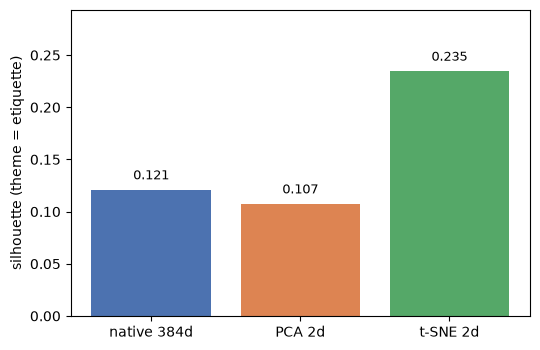

In [11]:
def silhouette_euclid(projetee, labels):
    return silhouette_score(projetee, np.array(labels), metric="euclidean")

SIL_NATIVE = silhouette_score(E_REF, labels_arr, metric="cosine")
SIL_PCA = silhouette_euclid(PROJ, LABELS)
SIL_TSNE = silhouette_euclid(PROJ_TSNE, LABELS)

print(f"silhouette native 384d (cosinus) : {SIL_NATIVE:.3f}")
print(f"silhouette PCA 2d   (euclidien) : {SIL_PCA:.3f}")
print(f"silhouette t-SNE 2d (euclidien) : {SIL_TSNE:.3f}")
print("Avertissement de methode : cosinus (natif) vs euclidien (plan) — la perte mesuree")
print("est celle de la reduction a deux axes, a metrique de plan pres.")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
noms_barres = ["native 384d", "PCA 2d", "t-SNE 2d"]
valeurs = [SIL_NATIVE, SIL_PCA, SIL_TSNE]
barres = ax.bar(noms_barres, valeurs, color=["#4c72b0", "#dd8452", "#55a868"])
for b, v in zip(barres, valeurs):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontsize=9)
ax.set_ylim(0, max(valeurs) * 1.25)
ax.set_ylabel("silhouette (theme = etiquette)")
plt.tight_layout()
plt.show()


### Lecture du résultat — ce qui se perd se mesure

Les trois chiffres, tels que mesurés : **0,121** dans l'espace natif (cosinus), **0,107** après PCA en deux axes, **0,235** après t-SNE. La PCA perd donc un peu (0,014) — deux axes linéaires ne portent pas toute la séparation d'un espace de 384 dimensions — tandis que le t-SNE **dépasse** la silhouette native. Ce n'est pas un paradoxe : le t-SNE optimise explicitement les voisinages locaux, et la silhouette mesure exactement cette propriété (une phrase est-elle plus proche de son thème que des autres) ; il optimise pour un critère voisin de celui qu'on mesure. Cela n'en fait pas une « meilleure » réduction pour autant : il a acheté cette structure locale en abandonnant les distances globales, et l'avertissement de méthode ci-dessus (cosinus natif contre euclidien de plan) interdit de lire ces trois chiffres comme un classement absolu de qualité.


## 9. Exercices

Trois exercices prolongent le carnet, sur le même corpus. Ils se complètent **sans erreur volontaire** : chaque stub s'exécute tel quel (il affiche un message et retourne `None`) ; c'est la version complétée qui doit reproduire les tableaux des sections précédentes.


### Exercice 1 — Combien d'axes pour 80 % de la variance ?

La section 6 affiche le cumul de variance expliquée pour l'espace de référence. Écrire la fonction qui, pour un espace `E` et un seuil `cible`, retourne le plus petit nombre `k` d'axes dont le cumul atteint la cible — puis la comparer entre l'espace 384d de MiniLM et l'espace 512d de DistilUSE.


In [12]:
def nb_axes_pour_variance(E, cible=0.80):
    # TODO etudiant : retourner le plus petit k tel que la somme des k premieres
    # variances expliquees (SVD de E centree) atteigne `cible`.
    # Indice : la section 6 calcule deja le cumul — il s'agit d'en faire une fonction.
    # Etape 1 : centrer E. Etape 2 : SVD. Etape 3 : cumsum de S**2 / sum(S**2).
    # Etape 4 : chercher le premier indice ou le cumul >= cible (attention : 1-indexe).
    print("Exercice 1 a completer — nb_axes_pour_variance")
    return None

# Piste de verification : avec cible=0.80 le resultat se compte en dizaines d'axes,
# et il est plus grand pour l'espace 512d de DistilUSE que pour celui de MiniLM.
_ = nb_axes_pour_variance(E_REF)


Exercice 1 a completer — nb_axes_pour_variance


### Exercice 2 — Un thème frontière : la cuisine moléculaire

Les thèmes du corpus sont étanches ; la cuisine moléculaire ne l'est pas. Ajouter des phrases qui mélangent cuisine et chimie, puis mesurer, pour chaque thème du corpus, la similarité moyenne de ces phrases : l'espace les place-t-il contre la cuisine, contre la technologie, ou entre les deux ?


In [13]:
PHRASES_FRONTIERE = [
    "La spherification d'un jus de fruit est une gelification en surface.",
    "L'azote liquide fige la sauce sans cristalliser l'eau qu'elle contient.",
    # TODO etudiant : ajoutez deux phrases qui melangent cuisine et chimie.
]

def place_du_theme_frontiere(nom_modele=REF):
    # TODO etudiant : encoder PHRASES_FRONTIERE avec `nom_modele` (prefixe ! cf section 3),
    # puis retourner, pour chaque phrase frontiere, le theme du corpus dont la
    # similarite moyenne est la plus haute.
    # Indice : regrouper par theme la moyenne des similarites cosinus avec les 10 phrases.
    print("Exercice 2 a completer — place_du_theme_frontiere")
    return None

_ = place_du_theme_frontiere()


Exercice 2 a completer — place_du_theme_frontiere


### Exercice 3 — Changer un modèle du banc

Remplacer `MODELE_EXERCICE` par un quatrième encodeur multilingue (un autre `*-multilingual-*` de votre choix), compléter la fonction de silhouette, et comparer le résultat au tableau de la section 4 : votre modèle sépare-t-il mieux les six thèmes que la référence de la série ?


In [14]:
MODELE_EXERCICE = "intfloat/multilingual-e5-small"  # TODO etudiant : un autre modele

def silhouette_d_un_modele(nom_hf, prefixe="", phrases=PHRASES, labels=LABELS):
    # TODO etudiant : encoder `phrases` avec le modele `nom_hf` (ajouter `prefixe`
    # aux phrases si le contrat du modele l'exige), puis retourner la silhouette
    # cosinus sur les etiquettes de themes.
    # Indice : la boucle de la section 4 contient tout le necessaire a generaliser.
    print("Exercice 3 a completer — silhouette_d_un_modele")
    return None

# Comparaison : la reference de la serie (REF) sert de seuil a battre.


## Continuer le parcours

L'espace est maintenant **visible**, et le banc a montré que la qualité d'un embedding se mesure avant de l'utiliser. La suite de la série consomme ces vecteurs :

- [`05-Stockage-Vectoriel.ipynb`](05-Stockage-Vectoriel.ipynb) — stocker et chercher les vecteurs à grande échelle ;
- [`05b-Stockage-Vectoriel-Serveur.ipynb`](05b-Stockage-Vectoriel-Serveur.ipynb) — le banc des moteurs, même logique de comparaison mesurée un étage plus haut (Qdrant, FAISS et pgvector sur un seul corpus) ;
- [`04-Tokenisation-From-Scratch.ipynb`](04-Tokenisation-From-Scratch.ipynb) — l'autre bout du pipeline : les unités que ces modèles encodent ;
- [`03-Embeddings-From-Scratch.ipynb`](03-Embeddings-From-Scratch.ipynb) — retour à la construction géométrique de l'espace, sans modèle pré-entraîné.

Cette cellule de navigation conclut le notebook sans modifier les exercices ni leurs sorties.
